# Dependencies

In [1]:
import warnings
warnings.simplefilter("ignore", UserWarning)

In [2]:
import sys
sys.path.append('../')

%load_ext autoreload
%autoreload 2

from libs import ios
from libs import vis
from libs.bibs import aps
from libs.inference import categorical
from libs.inference import numeric

# Setup

In [3]:
VERSION = 3
FN_PY_INF = f'../../results/v{VERSION}/gender/predictions_py/uniqueChineseAllGivenNames_PYgender_reg_mean_894_class_mean_607_1.csv'
FN_APS = '/data/datasets/APS/aps_data_processing/shares/aps-2022_25-10-01_e59319256d553035c40188457bb16edbfe02da04.zip'
FN_APS_OA_DEMOGRAPHICS = '/data/datasets/APS/aps_data_processing/shares/aps_20240130_2e52fdd7260ea462878821948a2a463ed9acb58a_20250120_APSOpenAlex/final_dataset.tar.gz'

In [4]:
vis.sns_paper_style()

# Data

## Ours

In [5]:
df_py = ios.load_csv(FN_PY_INF)
df_py.rename(columns={'givenname': 'ch_givenname', 'english_one':'py_givenname', 'pred':'ch_pred', 'pred_label':'ch_pred_label'}, inplace=True)
df_py.rename(columns={c:f"py_{c}" for c in df_py.columns if c.startswith('gender_')}, inplace=True)
df_py.loc[:, 'py_gender_mv'] = df_py.apply(lambda row: categorical.infer_gender_by_majority_vote(row['male_label_count'], row['female_label_count'], row['neutral_label_count']), axis=1)
df_py.shape


(46144, 19)

In [6]:
df_py.sample(5)

,ch_givenname,ch_pred,ch_pred_label,pop_CNKI,pop_NU,NLen,py_givenname,unique_name_count,py_gender_weighted_pop_CNKI,py_gender_weighted_pop_NU,py_gender_avg_all,py_gender_avg_CNKI,male_label_count,female_label_count,neutral_label_count,pop_sum_CNKI,pop_sum_NU,givennames,py_gender_mv
42362,进光,0.147559,male,2,4316.178445,2,jinguang,4,0.212725,0.206392,0.242650,0.242650,3,0,1,9,17794.054230,劲光#瑾光#进光#金光,male
45544,骁昀,0.328305,neutral,1,93.427828,2,xiaoyun,7,0.701654,0.715807,0.645910,0.645910,0,5,2,52,39156.703025,小云#小芸#晓云#晓允#晓筠#晓芸#骁昀,female
18,㫰,0.347726,male,0,0.000001,1,lang,23,0.278097,0.275064,0.344030,0.314901,20,0,3,26,460.921186,㫰#㮾#啷#埌#塱#崀#廊#朗#桹#榔#浪#烺#狼#琅#稂#筤#莨#蒗#蓢#螂#郎#锒#阆,male
460,兑,0.336905,male,0,0.747833,1,dui,8,NaN,0.336905,0.347046,NaN,8,0,0,0,0.747840,兑#堆#对#怼#碓#祋#镦#队,male
21059,寿亮,0.199827,male,2,2030.889097,2,shouliang,2,0.187364,0.178018,0.181132,0.181132,2,0,0,3,4873.695319,守良#寿亮,male


In [7]:
cols_py = ['ch_givenname','py_givenname','ch_pred', 'py_gender_weighted_pop_CNKI', 'py_gender_weighted_pop_NU', 'py_gender_avg_all', 'py_gender_avg_CNKI', 'ch_pred_label', 'py_gender_mv']
df_py[cols_py].head(1)

,ch_givenname,py_givenname,ch_pred,py_gender_weighted_pop_CNKI,py_gender_weighted_pop_NU,py_gender_avg_all,py_gender_avg_CNKI,ch_pred_label,py_gender_mv
0,㑇,zhou,0.347726,0.281119,0.279068,0.333601,0.280243,male,male


## APS (Karimi and van Buskirk)

In [8]:
_df_aps_authors = ios.read_csv_from_zip(FN_APS, 'data/authors.csv')
_df_aps_authors_names = ios.read_csv_from_zip(FN_APS, 'data/author_names.csv')
_df_aps_genders = ios.read_csv_from_zip(FN_APS, 'data/genders.csv')

df_aps = ios.pd.merge(_df_aps_authors, _df_aps_authors_names, how='inner', on='id_author', suffixes=("_a","_n"))
df_aps = ios.pd.merge(df_aps, _df_aps_genders, how='left', on='id_gender')
df_aps = df_aps[['id_author','id_author_name','name','gender','gender_nq', 'disambiguated']] # NOTE: it contains disambiguated True and False

print(f"APS authors: {_df_aps_authors.shape}")
print(f"APS authors names: {_df_aps_authors_names.shape}")
print(f"APS genders: {_df_aps_genders.shape}")
print(f"APS all authors merged: {df_aps.shape}")

df_aps_clean = aps.clean_aps_names(df_aps)
df_aps_clean_ch_py = aps.detect_pinyin_and_chinese_names(df_aps_clean)
df_aps_clean_ch_py.shape

APS authors: (874556, 4)
APS authors names: (948771, 4)
APS genders: (3, 2)
APS all authors merged: (948771, 6)


(874556, 21)

In [9]:
df_aps_ch = df_aps_clean_ch_py.query('ch_givenname.notna() and is_pinyin == True').copy()
df_aps_ch.rename(columns={'givenname_clean': 'py_givenname', 'gender_clean': 'py_gender_karimi', 'gender_nq_clean': 'py_gender_buskirk'}, inplace=True)
df_aps_ch.loc[:,'py_gender_buskirk'] = df_aps_ch.loc[:,'py_gender_buskirk'].replace({'gm': 'male', 'gf': 'female'})
df_aps_ch.shape

(1073, 21)

In [10]:
df_aps_ch.head(1)

,id_author,alternative_names,n_alternative_names,genders,genders_nq,py_gender_karimi,py_gender_buskirk,longest_name,longest_name_clean,py_givenname,...,is_pinyin_givenname,is_pinyin_familyname,is_pinyin,ch_name,ch_splitname,ch_familyname,ch_givenname,ch_translated_name_in_pinyin,ch_translated_familyname_in_pinyin,ch_translated_givenname_in_pinyin
301,301,"[Yu Liu (刘育), Yu Liu]",2,"[male, male]","[-, -]",male,unknown,Yu Liu (刘育),yu liu,yu,...,1,True,True,刘育,[刘 育],刘,育,liu yu,liu,yu


In [11]:
cols_aps = ['id_author','ch_givenname','py_givenname','py_gender_karimi','py_gender_buskirk']
df_aps_ch[cols_aps]

,id_author,ch_givenname,py_givenname,py_gender_karimi,py_gender_buskirk
301,301,育,yu,male,unknown
323,323,云旗,yunqi,male,unknown
390,390,永好,yonghao,male,unknown
429,429,玉敏,yumin,male,unknown
478,478,之恒,zhiheng,male,unknown
...,...,...,...,...,...
864200,864200,勋,xun,unknown,unknown
864209,864209,凯,kai,unknown,unknown
864213,864213,水,shui,unknown,unknown
864216,864216,刚,gang,unknown,unknown


## APS (Barolo)

In [12]:
df_oa_aps = ios.read_csv_from_tar_gz(FN_APS_OA_DEMOGRAPHICS, 'final_dataset/authors_demographics.csv')
print(f"OA APS authors: {df_oa_aps.shape}")

df_aps_barolo_clean = aps.clean_aps_names(df_oa_aps)
df_aps_barolo_clean_ch_py = aps.detect_pinyin_and_chinese_names(df_aps_barolo_clean)
print(f"APS barolo clean ch-py: {df_aps_barolo_clean_ch_py.shape}")

OA APS authors: (481012, 14)
APS barolo clean ch-py: (481012, 21)


In [13]:
df_aps_barolo_clean_ch_py.head(1)

,id_author,alternative_names,genders,genders_nq,gender_clean,gender_nq_clean,longest_name,n_alternative_names,longest_name_clean,givenname_clean,...,is_pinyin_givenname,is_pinyin_familyname,is_pinyin,ch_name,ch_splitname,ch_familyname,ch_givenname,ch_translated_name_in_pinyin,ch_translated_familyname_in_pinyin,ch_translated_givenname_in_pinyin
0,5000000199,"[d. marris morini, d. marris-morini, d. marris...",[Female],[Female],female,female,delphine marris-morini,5,delphine marris-morini,delphine,...,False,False,False,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>


In [14]:
df_aps_barolo_ch = df_aps_barolo_clean_ch_py.query('ch_givenname.notna()').copy()
df_aps_barolo_ch.rename(columns={'givenname_clean': 'py_givenname', 'gender_clean': 'py_gender_barolo'}, inplace=True)
df_aps_barolo_ch.loc[:,'py_gender_barolo'] = df_aps_barolo_ch.loc[:,'py_gender_barolo'].replace({'unisex': 'neutral'})
df_aps_barolo_ch.shape

(703, 21)

In [15]:
cols_aps_barolo = ['id_author','ch_givenname','py_givenname','py_gender_barolo']
df_aps_barolo_ch[cols_aps_barolo]

,id_author,ch_givenname,py_givenname,py_gender_barolo
112,5000028310,素兴,suxing,unknown
205,5000052235,王,wang,neutral
2074,5000519513,雯魏,yi-wen,unknown
2948,5000730597,承勋,cheng-xun,unknown
3757,5000937523,志超,chi-chiu,unknown
...,...,...,...,...
422405,5108049281,栋,dong,unknown
422429,5108051300,瑜兴,yu-xing,unknown
422463,5108055537,伟俞,yun-wei,unknown
422538,5108069602,飞袁,ye-fei,unknown


# Comparison

In [16]:
df_py[cols_py].head(1)

,ch_givenname,py_givenname,ch_pred,py_gender_weighted_pop_CNKI,py_gender_weighted_pop_NU,py_gender_avg_all,py_gender_avg_CNKI,ch_pred_label,py_gender_mv
0,㑇,zhou,0.347726,0.281119,0.279068,0.333601,0.280243,male,male


In [17]:
df_aps_ch_agg = (
    df_aps_ch
    .groupby(["ch_givenname", "py_givenname"], as_index=False)
    .agg({col: categorical.aggregate_gender for col in ["py_gender_karimi", "py_gender_buskirk"]})
)
df_aps_ch_agg = df_aps_ch_agg.groupby(["ch_givenname"]).filter(lambda x: x.py_givenname.nunique() == 1).copy() # TODO: check chinese/pinyin givenname extraction
df_aps_ch_agg

,ch_givenname,py_givenname,py_gender_karimi,py_gender_buskirk
0,一君,yijun,male,unknown
1,一周,yizhou,male,unknown
2,一昕,yixin,female,unknown
3,一洲,yizhou,male,unknown
4,一鹏,yipeng,male,male
...,...,...,...,...
785,鹏程,pengcheng,unknown,unknown
786,黎,li,male,male
787,龙,long,male,unknown
788,龙军,longjun,male,unknown


In [18]:
df_aps_barolo_ch_agg = (
    df_aps_barolo_ch
    .groupby(["ch_givenname", "py_givenname"], as_index=False)
    .agg({col: categorical.aggregate_gender for col in ["py_gender_barolo"]})
)
df_aps_barolo_ch_agg = df_aps_barolo_ch_agg.groupby(["ch_givenname"]).filter(lambda x: x.py_givenname.nunique() == 1).copy() # TODO: check chinese/pinyin givenname extraction
df_aps_barolo_ch_agg

,ch_givenname,py_givenname,py_gender_barolo
0,一平,yiping,unknown
1,一程,yi-cheng,unknown
2,丁,ding,female
3,万隆,wan-long,unknown
4,上,shang,unknown
...,...,...,...
597,龙,long,unknown
598,龙兴,long-xing,unknown
599,龙刘,yunlong,unknown
600,龙曾,xiang-long,unknown


In [19]:
assert df_py.ch_givenname.nunique() == df_py.shape[0]
assert df_aps_ch_agg.ch_givenname.nunique() == df_aps_ch_agg.shape[0]
assert df_aps_barolo_ch_agg.ch_givenname.nunique() == df_aps_barolo_ch_agg.shape[0]

In [20]:
df_py_genders = df_py.set_index('ch_givenname').join(df_aps_ch_agg.set_index('ch_givenname'), how='inner', lsuffix='_ours').join(df_aps_barolo_ch_agg.set_index('ch_givenname'), how='left', rsuffix='_barolo')
df_py_genders.shape

(675, 23)

In [21]:
cols = ['py_givenname_ours',
        'ch_pred','ch_pred_label','py_gender_mv',
        'py_gender_weighted_pop_CNKI','py_gender_weighted_pop_NU','py_gender_avg_all','py_gender_avg_CNKI',
        'py_givenname','py_gender_karimi','py_gender_buskirk',
        'py_givenname_barolo','py_gender_barolo']
df_py_genders[cols]

,py_givenname_ours,ch_pred,ch_pred_label,py_gender_mv,py_gender_weighted_pop_CNKI,py_gender_weighted_pop_NU,py_gender_avg_all,py_gender_avg_CNKI,py_givenname,py_gender_karimi,py_gender_buskirk,py_givenname_barolo,py_gender_barolo
ch_givenname,,,,,,,,,,,,,
丁,ding,0.377206,neutral,male,0.334414,0.338034,0.356946,0.360417,ding,male,unknown,ding,female
业,ye,0.324929,neutral,male,0.426069,0.453970,0.395760,0.447648,ye,male,unknown,NaN,NaN
东,dong,0.272237,male,male,0.336049,0.349730,0.334870,0.332124,dong,male,unknown,NaN,NaN
丹,dan,0.640028,female,male,0.630809,0.629659,0.394949,0.524874,dan,male,unknown,NaN,NaN
为,wei,0.256074,male,male,0.326056,0.311796,0.373857,0.395385,wei,male,unknown,NaN,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...
鸿业,hongye,0.154266,male,male,0.237776,0.408090,0.297120,0.297120,hongye,male,unknown,hongye,unknown
鸿儒,hongru,0.156665,male,male,0.333011,0.283107,0.309338,0.309338,hongru,male,unknown,NaN,NaN
鹏举,pengju,0.211861,male,male,0.211861,0.211861,0.211861,0.211861,pengju,male,unknown,NaN,NaN


In [22]:
METHOD_LABELS = {
        "py_gender_karimi": "Karimi et al. (2016)",
        "py_gender_buskirk": "van Buskirk et al. (2023)",
        'py_gender_barolo': 'Barolo et al. (2025)',
        "py_gender_mv": "Ours (PY)",
        "ch_pred_label": "Ours (CH)"
    }

METHOD_ORDER = ['py_gender_karimi', "py_gender_buskirk", 'py_gender_barolo','py_gender_mv','ch_pred_label']

PINYIN_AGG_LABELS = {'py_gender_avg_all': 'Mean (all chars)', 
                     'py_gender_weighted_pop_NU': 'Weighted pop.', 
                     'py_gender_avg_CNKI': 'Mean (CNKI chars)', 
                     'py_gender_weighted_pop_CNKI': 'Weighted CNKI pop.'}

========== py_gender_avg_all ==========


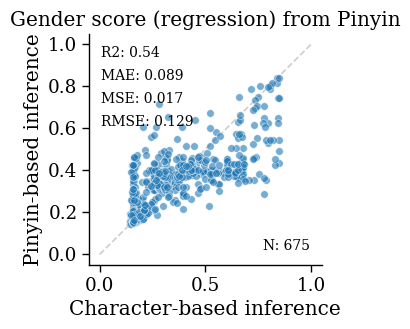

========== py_gender_weighted_pop_NU ==========


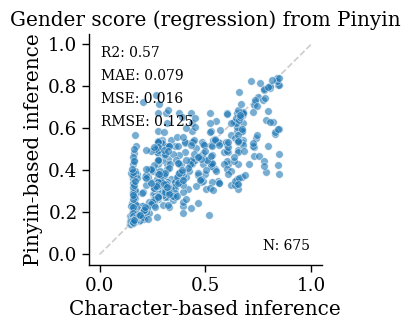

========== py_gender_avg_CNKI ==========


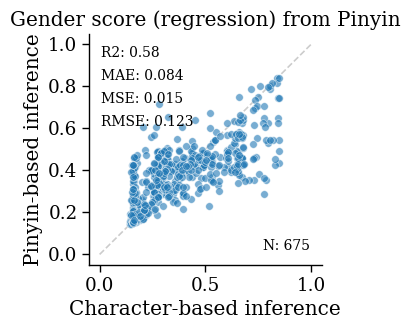

========== py_gender_weighted_pop_CNKI ==========


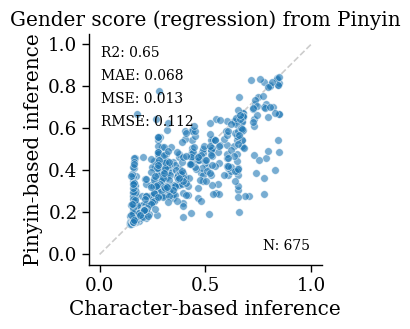

In [ ]:
rmse_pred_py_test = None

for col, label in PINYIN_AGG_LABELS.items():

    print(f"========== {col} ==========")

    df = df_py_genders.dropna(subset=[col])
    
    mae_pred, mse_pred, rmse_pred, r2_pred = numeric.get_performance(df, 'ch_pred', col)
    performance_py = {'mae': mae_pred, 'mse': mse_pred, 'rmse': rmse_pred, 'r2': r2_pred}

    _, _ = vis.plot_regression_performance(df, 'ch_pred', col, 
                                    metrics = performance_py,
                                    figsize=(3, 3), 
                                    title=f"Gender score (regression) from Pinyin",
                                    xlabel="Character-based inference", 
                                    ylabel="Pinyin-based inference",
                                    markersize=30,
                                    markeralpha=0.6,
                                    )
    vis.plt.show()
    vis.plt.close()


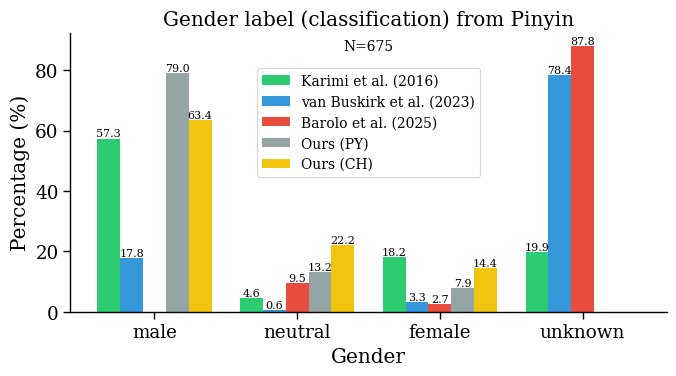

In [24]:
fig, ax = vis.plot_gender_comparison(
    df_py_genders,
    method_order=METHOD_ORDER,
    method_labels=METHOD_LABELS,
    xlabel_order=categorical.GENDER_LABELS_3 + [categorical.UNKNOWN],
    colors=["#2ecc71", "#3498db", "#e74c3c", "#95a5a6", "#f1c40f"],
    use_percentages=True,
    annotate_bars=True,
    title=f"Gender label (classification) from Pinyin",
    n_annotation_kwargs={"fontsize": 10, "x": 0.5, "y":0.98, "ha": "center"} ,
    legend_kwargs={"loc": "upper center", "bbox_to_anchor": (0.5, 0.9), 'fontsize': 10},
    figsize=(7, 4)
)
vis.plt.show()
vis.plt.close()

In [25]:

# 1) Pairwise agreement (accuracy) matrix — proportion of rows where methods agree:
agreement_gt_ch = categorical.pairwise_agreement(df_py_genders, METHOD_ORDER)
print("Pairwise agreement (accuracy) matrix — proportion of rows where methods agree:")
display(agreement_gt_ch.round(2))

# 2) Cohen's Kappa — agreement corrected for chance
kappa_gt_ch = categorical.pairwise_kappa(df_py_genders, METHOD_ORDER)
print("\nCohen's Kappa matrix (chance-corrected agreement):")
display(kappa_gt_ch.round(2))

Pairwise agreement (accuracy) matrix — proportion of rows where methods agree:


,py_gender_karimi,py_gender_buskirk,py_gender_barolo,py_gender_mv,ch_pred_label
py_gender_karimi,1.00,0.28,0.12,0.51,0.44
py_gender_buskirk,0.28,1.00,0.58,0.17,0.14
py_gender_barolo,0.12,0.58,1.00,0.01,0.03
py_gender_mv,0.51,0.17,0.01,1.00,0.72
ch_pred_label,0.44,0.14,0.03,0.72,1.00



Cohen's Kappa matrix (chance-corrected agreement):


,py_gender_karimi,py_gender_buskirk,py_gender_barolo,py_gender_mv,ch_pred_label
py_gender_karimi,1.00,0.02,-0.01,0.06,0.07
py_gender_buskirk,0.02,1.00,-0.01,0.03,0.02
py_gender_barolo,-0.01,-0.01,1.00,0.01,0.00
py_gender_mv,0.06,0.03,0.01,1.00,0.38
ch_pred_label,0.07,0.02,0.00,0.38,1.00
